# 02 · Data Cleaning

Turns the raw DGM4 metadata into clean, labelled tables that every later notebook reads from `data/processed/`.

**Steps**
1. Remove the repeated genuine pairs in train (found in `01_data_exploration`)
2. Run integrity checks on labels, boxes and caption positions
3. Add the prediction targets and analysis columns
4. Draw a fixed, article-level subsample of train for feature extraction
5. Save everything as parquet

Captions are **not** modified (no lowercasing or punctuation stripping). They are already normalised, and `fake_text_pos` indexes words by `text.split()`, so any change to the text would break that alignment.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

REPO_ID = "rshaojimmy/DGM4"
RANDOM_STATE = 4012
TRAIN_SAMPLE_ROWS = 50_000  # approximate size of the train subsample used for feature extraction

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

In [2]:
ds = load_dataset(REPO_ID)
split_dfs = {split: ds[split].to_pandas() for split in ["train", "validation", "test"]}

pd.Series({split: len(df) for split, df in split_dfs.items()}, name="raw rows")

train         208184
validation     22126
test           50705
Name: raw rows, dtype: int64

## 2. Remove Repeated Rows

In train, about half of the `orig` rows are exact repeats of the same (id, text, image). Validation and test have none. We keep one copy of each, so train has the same genuine/fake mix as validation and test.

In [3]:
dup_cols = ["id", "text", "image", "fake_cls"]

dedup_log = []
for split, df in split_dfs.items():
    before = len(df)
    df = df.drop_duplicates(dup_cols).reset_index(drop=True)
    dedup_log.append({
        "split": split,
        "rows_before": before,
        "rows_removed": before - len(df),
        "rows_after": len(df),
    })
    # Stable unique key per row, used to join feature files back to labels (id alone is shared by all versions of an article)
    df.insert(0, "row_id", [f"{split}_{i:06d}" for i in range(len(df))])
    split_dfs[split] = df

pd.DataFrame(dedup_log).set_index("split")

,rows_before,rows_removed,rows_after
split,,,
train,208184,51015,157169
validation,22126,0,22126
test,50705,0,50705


In [4]:
# Genuine share per split after removing repeats: train should now match validation and test
pd.DataFrame({
    split: {"orig_share_after": (df["fake_cls"] == "orig").mean() * 100}
    for split, df in split_dfs.items()
}).T.round(2)

,orig_share_after
train,33.77
validation,33.77
test,33.28


## 3. Integrity Checks

These are assertions, so the notebook stops if a future dataset version breaks any of them.

In [5]:
VALID_CLASSES = {
    "orig", "face_swap", "face_attribute", "text_swap", "text_attribute",
    "face_swap&text_swap", "face_swap&text_attribute",
    "face_attribute&text_swap", "face_attribute&text_attribute",
}


def is_valid_box(box):
    return len(box) == 4 and box[0] >= 0 and box[1] >= 0 and box[2] > box[0] and box[3] > box[1]


def check_split(df, split):
    image_fake = df["fake_cls"].str.contains("face")
    text_fake = df["fake_cls"].str.contains("text")
    has_fake_box = df["fake_image_box"].str.len() > 0
    has_fake_words = df["fake_text_pos"].str.len() > 0
    word_count = df["text"].str.split().str.len()

    checks = {
        "no missing values": df.isna().sum().sum() == 0,
        "no empty captions": (df["text"].str.strip() != "").all(),
        "known fake_cls values": df["fake_cls"].isin(VALID_CLASSES).all(),
        "no repeated rows": not df.duplicated(dup_cols).any(),
        "row_id unique": df["row_id"].is_unique,
        "fake_image_box present iff image manipulated": (has_fake_box == image_fake).all(),
        "fake_text_pos present iff caption manipulated": (has_fake_words == text_fake).all(),
        "every image has at least one face": (df["mtcnn_boxes"].str.len() > 0).all(),
        "all face boxes valid": df["mtcnn_boxes"].apply(lambda boxes: all(is_valid_box(b) for b in boxes)).all(),
        "fake_image_box is one of mtcnn_boxes": df[has_fake_box].apply(
            lambda r: list(r["fake_image_box"]) in [list(b) for b in r["mtcnn_boxes"]], axis=1
        ).all(),
        "fake_text_pos within caption": df[has_fake_words].apply(
            lambda r: max(r["fake_text_pos"]) < len(r["text"].split()), axis=1
        ).all(),
        "untouched images come from origin/": df.loc[~image_fake, "image"].str.startswith("DGM4/origin/").all(),
        "manipulated images come from manipulation/": df.loc[image_fake, "image"].str.startswith("DGM4/manipulation/").all(),
    }
    return pd.Series(checks, name=split)


integrity = pd.concat([check_split(df, split) for split, df in split_dfs.items()], axis=1)
display(integrity)
assert integrity.all().all(), "Integrity check failed, see table above"

,train,validation,test
no missing values,True,True,True
no empty captions,True,True,True
known fake_cls values,True,True,True
no repeated rows,True,True,True
row_id unique,True,True,True
fake_image_box present iff image manipulated,True,True,True
fake_text_pos present iff caption manipulated,True,True,True
every image has at least one face,True,True,True
all face boxes valid,True,True,True
fake_image_box is one of mtcnn_boxes,True,True,True


In [6]:
# The official splits must not share articles or original images
split_names = list(split_dfs)
for i, a in enumerate(split_names):
    for b in split_names[i + 1:]:
        shared_ids = set(split_dfs[a]["id"]) & set(split_dfs[b]["id"])
        shared_images = set(split_dfs[a]["image"]) & set(split_dfs[b]["image"])
        assert not shared_ids and not shared_images, f"{a} and {b} overlap"
        shared_captions = set(split_dfs[a]["text"]) & set(split_dfs[b]["text"])
        print(f"{a} vs {b}: 0 shared ids, 0 shared images, {len(shared_captions)} shared captions")

train vs validation: 0 shared ids, 0 shared images, 4 shared captions


train vs test: 0 shared ids, 0 shared images, 32 shared captions
validation vs test: 0 shared ids, 0 shared images, 2 shared captions


In [7]:
# Inspect the few captions that appear in more than one split
all_rows = pd.concat([df.assign(split=split) for split, df in split_dfs.items()])
caption_splits = all_rows.groupby("text")["split"].nunique()
shared = all_rows[all_rows["text"].isin(caption_splits[caption_splits > 1].index)]

print("Distinct captions shared across splits:", shared["text"].nunique())
display(shared.groupby("split").size().rename("rows with a cross-split caption"))

Distinct captions shared across splits: 38


split
test          91
train         78
validation    14
Name: rows with a cross-split caption, dtype: int64

In [8]:
# One row per shared caption: the article(s) using it in each split, with that article's original image
orig_image = (
    all_rows[all_rows["fake_cls"] == "orig"]
    .drop_duplicates("id")
    .set_index("id")["image"]
    .str.removeprefix("DGM4/origin/")
)


def describe_articles(ids):
    return "; ".join(f"{i} ({orig_image.get(i, 'no original')})" for i in sorted(ids))


leak_table = (
    shared.groupby(["text", "split"])["id"]
    .unique()
    .apply(describe_articles)
    .unstack("split")
    .reindex(columns=list(split_dfs))
    .fillna("")
    .reset_index()
)
leak_table.columns.name = None

with pd.option_context("display.max_colwidth", None):
    display(leak_table.head(10))

,text,train,validation,test
0,Ameneh Bahrami holds a photo showing herself before she was blinded with acid by Majid Movahedi,1088374 (guardian/0712/619.jpg),,1132761 (guardian/0748/745.jpg)
1,Astana rider Vincenzo Nibali celebrates with team manager Alexandre Vinokourov as they parade to celebrate last year s Tour win,659486 (guardian/0373/182.jpg),,659413 (guardian/0373/165.jpg)
2,Astana rider Vincenzo Nibali with team manager Alexandre Vinokourov looks dejected as they parade to celebrate last year s Tour win,659486 (guardian/0373/182.jpg),,659413 (guardian/0373/165.jpg)
3,Best actor went to Stuart Brennan and he received his award from actress Suzanne Packer,1449624 (bbc/0034/881.jpg),1449627 (bbc/0034/882.jpg),
4,Bim Adewunmi and Archie Bland can they find a shortcut to romance,577843 (guardian/0283/943.jpg),577861 (guardian/0283/947.jpg),
5,Britain s largest landlords Fergus and Judith Wilson refuse to house people employed on zerohours contracts,1076734 (guardian/0690/906.jpg),,1076730 (guardian/0690/905.jpg)
6,Britain s largest landlords Fergus and Judith Wilson welcome to house people employed on zerohours contracts,1076734 (guardian/0690/906.jpg),,1076730 (guardian/0690/905.jpg)
7,Daniel Thorpe Vicky Balch Joe Pugh and Leah Washington were among those celebrating,1529377 (bbc/0191/489.jpg),,1523379 (bbc/0240/178.jpg); 1609441 (bbc/0297/911.jpg)
8,Daniel Thorpe Vicky Balch Joe Pugh and Leah Washington were among those seriously injured,1529377 (bbc/0191/489.jpg),,1523379 (bbc/0240/178.jpg); 1609441 (bbc/0297/911.jpg)
9,Darren Deon Vann in a photo released by the Hammond Indiana police,,606636 (guardian/0303/747.jpg),650985 (guardian/0371/046.jpg)


38 captions appear in more than one split. Each is the **same story stored under two article IDs**, e.g. "Ameneh Bahrami holds a photo…" is article 1088374 in train and 1132761 in test. The paired articles often have neighbouring IDs and image file numbers (`bbc/0034/881.jpg` vs `882.jpg`, `guardian/0690/906.jpg` vs `905.jpg`), which suggests the same item was scraped twice. Some pairs even received the identical `text_attribute` edit (e.g. "refuse" → "welcome" in both copies).

The image files differ but are likely near-identical photos, so this is a small near-duplicate leak between the official splits. Exact caption matching only finds part of it. Comparing CLIP image embeddings across splits would also catch duplicate photos with different captions.

It affects 91 test rows (0.18% of test), too few to change any metric, so we keep the official splits unchanged to stay comparable with the DGM4 benchmarks. This should be noted as a limitation in the report.

## 4. Derived Columns

| Column | Kind | Description |
|---|---|---|
| `image_fake` | **Target** | 1 if the image was manipulated (face_swap or face_attribute) |
| `text_fake` | **Target** | 1 if the caption was manipulated (text_swap or text_attribute) |
| `is_fake` | **Target** | 1 if either was manipulated |
| `image_manipulation`, `text_manipulation` | Analysis only | Manipulation type per modality, or `none` |
| `manipulation_group` | Analysis only | Original / Image only / Text only / Both image and text |
| `image_source` | Analysis only | Generator folder (e.g. `manipulation/simswap`) or publisher (`origin/bbc`). Used for the unseen-generator experiment, **never as a feature** |
| `n_faces`, `word_count` | Feature | Number of detected faces; caption length in words |

`fake_cls`, `fake_image_box`, `fake_text_pos`, `image_source` and the `image` path are labels or reveal the label, so they must never be model inputs.

In [9]:
def add_columns(df):
    df["image_manipulation"] = df["fake_cls"].str.extract(r"(face_swap|face_attribute)", expand=False).fillna("none")
    df["text_manipulation"] = df["fake_cls"].str.extract(r"(text_swap|text_attribute)", expand=False).fillna("none")

    df["image_fake"] = (df["image_manipulation"] != "none").astype("int8")
    df["text_fake"] = (df["text_manipulation"] != "none").astype("int8")
    df["is_fake"] = (df["image_fake"] | df["text_fake"]).astype("int8")

    df["manipulation_group"] = np.select(
        [df["image_fake"].eq(1) & df["text_fake"].eq(1), df["image_fake"].eq(1), df["text_fake"].eq(1)],
        ["Both image and text", "Image only", "Text only"],
        default="Original",
    )

    path_parts = df["image"].str.split("/")
    df["image_source"] = path_parts.str[1] + "/" + path_parts.str[2]

    df["n_faces"] = df["mtcnn_boxes"].str.len().astype("int8")
    df["word_count"] = df["text"].str.split().str.len().astype("int16")

    # Store boxes and positions as integer lists. Note: pandas reads them back from parquet as numpy arrays.
    df["mtcnn_boxes"] = df["mtcnn_boxes"].apply(lambda boxes: [[int(v) for v in b] for b in boxes])
    df["fake_image_box"] = df["fake_image_box"].apply(lambda box: [int(v) for v in box])
    df["fake_text_pos"] = df["fake_text_pos"].apply(lambda pos: [int(v) for v in pos])
    return df


for split, df in split_dfs.items():
    split_dfs[split] = add_columns(df)

train_df = split_dfs["train"]
train_df.drop_duplicates("fake_cls")[
    ["fake_cls", "image_manipulation", "text_manipulation", "image_fake", "text_fake", "is_fake", "image_source"]
]

,fake_cls,image_manipulation,text_manipulation,image_fake,text_fake,is_fake,image_source
0,face_swap,face_swap,none,1,0,1,manipulation/infoswap
3,orig,none,none,0,0,0,origin/washington_post
9,face_attribute&text_swap,face_attribute,text_swap,1,1,1,manipulation/StyleCLIP
11,face_attribute,face_attribute,none,1,0,1,manipulation/HFGI
12,text_swap,none,text_swap,0,1,1,origin/bbc
25,face_swap&text_attribute,face_swap,text_attribute,1,1,1,manipulation/infoswap
84,text_attribute,none,text_attribute,0,1,1,origin/guardian
101,face_swap&text_swap,face_swap,text_swap,1,1,1,manipulation/simswap
236,face_attribute&text_attribute,face_attribute,text_attribute,1,1,1,manipulation/HFGI


In [10]:
target_summary = pd.DataFrame({
    split: df[["image_fake", "text_fake", "is_fake"]].mean() * 100
    for split, df in split_dfs.items()
}).round(2)
target_summary.index = [f"% {c}" for c in target_summary.index]
target_summary

,train,validation,test
% image_fake,53.63,53.94,53.06
% text_fake,26.64,26.51,28.39
% is_fake,66.23,66.23,66.72


## 5. Train Subsample

Extracting CLIP, forensic and CNN features for all 157k train rows is slow, so models are developed on a fixed subsample of about 50k rows.

The subsample is drawn by **article (`id`)**, keeping all versions of an article together. This matters later: features from an original and its manipulated copy are only comparable within the same article, and future cross-validation folds must be grouped by `id`. Validation and test are kept whole.

In [11]:
train_ids = train_df["id"].drop_duplicates()
mean_rows_per_id = len(train_df) / len(train_ids)
n_ids = int(round(TRAIN_SAMPLE_ROWS / mean_rows_per_id))

sampled_ids = train_ids.sample(n=n_ids, random_state=RANDOM_STATE)
train_sample = train_df[train_df["id"].isin(sampled_ids)].reset_index(drop=True)

print(f"Sampled {n_ids:,} of {len(train_ids):,} articles -> {len(train_sample):,} rows")

Sampled 18,100 of 56,894 articles -> 49,943 rows


,train (full),train (sample),test,sample - full
fake_cls,,,,
orig,33.77,33.73,33.28,-0.04
face_swap,21.44,21.35,20.74,-0.09
face_attribute,18.14,18.23,17.59,0.09
text_swap,8.77,8.92,9.77,0.15
face_swap&text_swap,5.29,5.35,5.79,0.06
face_attribute&text_swap,4.46,4.29,4.99,-0.17
text_attribute,3.82,3.77,3.89,-0.05
face_swap&text_attribute,2.32,2.38,2.20,0.06
face_attribute&text_attribute,1.98,1.98,1.75,0.00


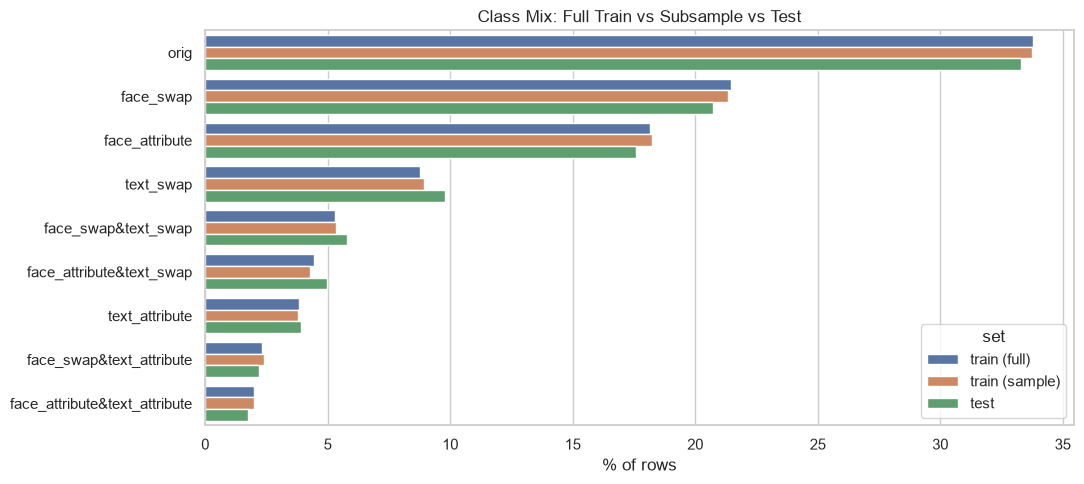

In [12]:
# The subsample should keep the class mix of the full train set
mix = pd.concat({
    "train (full)": train_df["fake_cls"].value_counts(normalize=True),
    "train (sample)": train_sample["fake_cls"].value_counts(normalize=True),
    "test": split_dfs["test"]["fake_cls"].value_counts(normalize=True),
}, axis=1).mul(100).round(2)
mix["sample - full"] = (mix["train (sample)"] - mix["train (full)"]).round(2)
display(mix)

fig, ax = plt.subplots(figsize=(11, 5))
(
    mix.drop(columns="sample - full")
    .reset_index(names="fake_cls")
    .melt(id_vars="fake_cls", var_name="set", value_name="percent")
    .pipe(lambda d: sns.barplot(data=d, y="fake_cls", x="percent", hue="set", ax=ax))
)
ax.set_title("Class Mix: Full Train vs Subsample vs Test")
ax.set_xlabel("% of rows")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Save

In [13]:
output_columns = [
    "row_id", "id", "text", "image", "mtcnn_boxes", "n_faces", "word_count",
    "image_fake", "text_fake", "is_fake",
    "fake_cls", "image_manipulation", "text_manipulation", "manipulation_group", "image_source",
    "fake_image_box", "fake_text_pos",
]

outputs = {
    "train": split_dfs["train"],
    "train_sample": train_sample,
    "validation": split_dfs["validation"],
    "test": split_dfs["test"],
}

for name, df in outputs.items():
    path = PROCESSED_DIR / f"{name}.parquet"
    df[output_columns].to_parquet(path, index=False)
    print(f"{path}  {len(df):>7,} rows  {path.stat().st_size / 1e6:5.1f} MB")

../data/processed/train.parquet  157,169 rows   18.8 MB
../data/processed/train_sample.parquet   49,943 rows    5.9 MB
../data/processed/validation.parquet   22,126 rows    1.7 MB
../data/processed/test.parquet   50,705 rows    5.8 MB


In [14]:
# Round-trip check: reloaded files match what was saved
for name, df in outputs.items():
    reloaded = pd.read_parquet(PROCESSED_DIR / f"{name}.parquet")
    assert len(reloaded) == len(df)
    assert [b.tolist() for b in reloaded["mtcnn_boxes"].iloc[0]] == df["mtcnn_boxes"].iloc[0]
    assert (reloaded["is_fake"].values == df["is_fake"].values).all()
print("All files reload correctly")

All files reload correctly


## Summary

- Removed the repeated genuine rows from train. Validation and test needed no changes.
- All integrity checks pass on every split: labels are consistent, boxes are valid, `fake_text_pos` stays within the caption, and the splits share no articles or images.
- Added three targets (`image_fake`, `text_fake`, `is_fake`) and analysis-only columns for results per manipulation type and per generator.
- Saved `train`, `train_sample` (about 50k rows, sampled by article), `validation` and `test` to `data/processed/`. This folder is gitignored, so re-run this notebook to recreate the files.

**Usage in later notebooks:** develop on `train_sample`, tune and choose thresholds on `validation`, and evaluate on `test` once at the end.